<a href="https://colab.research.google.com/github/bspineda27/areasinundadasff/blob/main/Stefanny_Pineda_7_2_Colab_Clasificacion_Sentinel2_GEE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 7.2 Clasificación supervisada de imágenes satelitales: SVM, Random Forest y Gradient Boosting en Earth Engine
### Especialización en Sistemas de Información Geográfica – Módulo de Big Data Espacial
**Universidad Antonio Nariño** · Semana 3 · Clase 7 (jueves 5 de noviembre de 2026)

**Docente:** Ing. Jorge Armando Alpala Aguilar, MSc. en Geomática – jalpala606@uan.edu.co

---

### ¿Qué vamos a hacer?

Clasificaremos la cobertura del suelo de un área de **Santander** (Bucaramanga, Girón, Floridablanca, Piedecuesta,
Lebrija: ~1.500 km²) con un compuesto Sentinel-2 y tres clasificadores **entrenados dentro de Earth Engine**, y
evaluaremos cada uno con **matriz de confusión, exactitud global, exactitud de productor/usuario e índice Kappa**.

| Bloque | Tema |
|---|---|
| 1 | Teoría: flujo de clasificación supervisada; RF, SVM y Gradient Boosting; métricas de exactitud temática |
| 2 | Área, compuesto Sentinel-2 (temporada seca 2024), variables (bandas, índices, textura, terreno) |
| 3 | Muestras de entrenamiento y validación: ESA WorldCover 2021 como referencia; estratificación; partición espacial |
| 4 | Entrenar `smileRandomForest`, `libsvm` y `smileGradientTreeBoost`; clasificar; mapa comparativo |
| 5 | Evaluación: matriz de confusión, exactitud, Kappa, exactitud por clase; importancia de variables |
| 6 | Posprocesamiento (filtro de moda), áreas por clase, exportación |

---
# Bloque 1. Fundamentos

## 1.1 Flujo de una clasificación supervisada de imágenes

```
 Imagen(es) ──▶ Preprocesamiento ──▶ Variables (X) ──▶ Muestras etiquetadas ──▶ Entrenamiento ──▶ Clasificación ──▶ Evaluación ──▶ Posproceso
   S2 L2A       nubes, compuesto      bandas, índices,    campo / referencia      RF, SVM, GBT      mapa de clases    matriz de       filtro de moda,
                                      textura, terreno    (WorldCover, DW)                                            confusión, κ    áreas
```

## 1.2 Los tres clasificadores

| Algoritmo | Idea | Fortalezas | Debilidades | En EE |
|---|---|---|---|---|
| **Random Forest** | Promedio de muchos árboles entrenados con bootstrap y variables aleatorias | Robusto, pocos hiperparámetros, importancia de variables, rápido | Puede sesgar hacia clases mayoritarias | `ee.Classifier.smileRandomForest(numberOfTrees)` |
| **SVM** (máquina de vectores de soporte) | Busca el hiperplano de máximo margen; con *kernel* RBF separa clases no lineales | Muy bueno con pocas muestras bien separadas | Lento con muchas muestras; sensible a escala y a `gamma`/`cost` | `ee.Classifier.libsvm(kernelType='RBF', gamma, cost)` |
| **Gradient Boosting** (GBT) | Árboles entrenados en secuencia, cada uno corrige los errores del anterior | Suele dar la mayor exactitud | Más hiperparámetros, riesgo de sobreajuste, más lento | `ee.Classifier.smileGradientTreeBoost(numberOfTrees, shrinkage)` |

## 1.3 Métricas de exactitud temática

Con una **matriz de confusión** (filas = referencia, columnas = clasificado):

* **Exactitud global** = aciertos / total.
* **Exactitud del productor** (por clase) = aciertos de la clase / total de referencia de la clase (1 − error de omisión).
* **Exactitud del usuario** (por clase) = aciertos de la clase / total clasificado como la clase (1 − error de comisión).
* **Índice Kappa** (κ) = (p₀ − pₑ)/(1 − pₑ): acuerdo corregido por el azar. Referencia habitual: κ > 0,8 excelente, 0,6-0,8 bueno.
  (Hoy se recomienda reportar también F1 por clase; Kappa sigue siendo el estándar en la literatura de percepción remota.)

**Muestras de validación independientes:** nunca evaluar con las mismas muestras de entrenamiento; y, como vimos
en la Clase 6, separarlas **espacialmente** para no sobreestimar.

In [2]:
import importlib, subprocess, sys
for paquete, modulo in [("earthengine-api", "ee"), ("geemap", "geemap")]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=False)
import os, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ee, geemap
warnings.filterwarnings("ignore")
PROYECTO_GEE = "accesoparques"
try:
    ee.Initialize(project=PROYECTO_GEE)
except Exception:
    ee.Authenticate(); ee.Initialize(project=PROYECTO_GEE)
os.makedirs("salidas_clase7", exist_ok=True)
print("EE listo")

EE listo


---
# Bloque 2. Área de estudio, compuesto y variables

Además de bandas e índices añadimos **textura** (desviación estándar local del NIR en una ventana de 5×5 píxeles,
útil para separar construido de suelo desnudo) y **terreno** (elevación y pendiente). Todas las variables se
calculan en EE a 10 m.

In [3]:
gaul = ee.FeatureCollection("FAO/GAUL/2025/level2").filter(ee.Filter.eq("GAUL1_NAME", "Santander"))
area = gaul.filter(ee.Filter.inList("GAUL2_NAME", ["Bucaramanga", "Floridablanca", "Girón", "Piedecuesta", "Lebrija"]))
aoi = area.geometry()
print("Área de estudio: %.0f km²" % (aoi.area(100).getInfo() / 1e6))

def enmascarar_nubes(img):
    scl = img.select("SCL")
    m = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))
    return img.updateMask(m).divide(10000).copyProperties(img, ["system:time_start"])

s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(aoi)
        .filterDate("2023-12-01", "2024-03-31").filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 40)).map(enmascarar_nubes))
print("Escenas usadas:", s2.size().getInfo())
comp = s2.median().clip(aoi)

BANDAS = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
ndvi = comp.normalizedDifference(["B8", "B4"]).rename("NDVI")
ndwi = comp.normalizedDifference(["B3", "B8"]).rename("NDWI")
ndbi = comp.normalizedDifference(["B11", "B8"]).rename("NDBI")
bsi = comp.expression("((SWIR + RED) - (NIR + BLUE)) / ((SWIR + RED) + (NIR + BLUE))",
                      {"SWIR": comp.select("B11"), "RED": comp.select("B4"), "NIR": comp.select("B8"), "BLUE": comp.select("B2")}).rename("BSI")
textura = comp.select("B8").reduceNeighborhood(ee.Reducer.stdDev(), ee.Kernel.square(2)).rename("textura_NIR")
srtm = ee.Image("USGS/SRTMGL1_003")
terreno = srtm.rename("elevacion").addBands(ee.Terrain.slope(srtm).rename("pendiente"))

variables = comp.select(BANDAS).addBands([ndvi, ndwi, ndbi, bsi, textura]).addBands(terreno).toFloat()
VARS = variables.bandNames().getInfo()
print(len(VARS), "variables:", VARS)

Área de estudio: 1294 km²
Escenas usadas: 58
17 variables: ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12', 'NDVI', 'NDWI', 'NDBI', 'BSI', 'textura_NIR', 'elevacion', 'pendiente']


---
# Bloque 3. Muestras de entrenamiento y validación

Sin trabajo de campo, usamos como referencia **ESA WorldCover 2021** (10 m, exactitud global ~77 %) y reagrupamos
sus clases en 5: árboles, herbáceo (pastizal, arbustos y cultivos, inseparables en temporada seca), construido, suelo
desnudo y agua. Tomamos una **muestra
estratificada** (igual número de puntos por clase) y la partimos **espacialmente**: los puntos del oeste
entrenan, los del este validan (así evitamos la fuga de información entre vecinos).

> En un proyecto real, las muestras deben venir de campo, fotointerpretación o productos de mayor calidad, y la
> referencia debe ser independiente del clasificador.

In [4]:
CLASES = {1: "Arboles", 2: "Herbaceo", 3: "Construido", 4: "Suelo_desnudo", 5: "Agua"}
PALETA = ["006400", "ffff4c", "fa0000", "b4b4b4", "0064c8"]
wc = ee.ImageCollection("ESA/WorldCover/v200").first().clip(aoi)
# Reclasificación: 10 árboles→1; 20 arbustos, 30 pastizal y 40 cultivos→2 (herbáceo); 50 construido→3; 60 suelo→4; 80 agua y 90 humedal→5
referencia = wc.remap([10, 20, 30, 40, 50, 60, 80, 90], [1, 2, 2, 2, 3, 4, 5, 5]).rename("clase")

apilado = variables.addBands(referencia)
muestras = apilado.stratifiedSample(numPoints=800, classBand="clase", region=aoi, scale=10, seed=7, geometries=True, tileScale=4)
print("Muestras por clase:", muestras.aggregate_histogram("clase").getInfo())

# Partición espacial: la mitad occidental (longitud menor que la mediana) entrena; la oriental valida
muestras = muestras.map(lambda f: f.set("lon", f.geometry().coordinates().get(0)))
lon_mediana = ee.Number(muestras.aggregate_array("lon").reduce(ee.Reducer.median()))
entrenamiento = muestras.filter(ee.Filter.lt("lon", lon_mediana))
validacion = muestras.filter(ee.Filter.gte("lon", lon_mediana))
print("Longitud de corte: %.3f" % lon_mediana.getInfo())
print("Entrenamiento:", entrenamiento.size().getInfo(), "| Validación:", validacion.size().getInfo())

Muestras por clase: {'1': 800, '2': 800, '3': 800, '4': 800, '5': 800}
Longitud de corte: -73.096
Entrenamiento: 1995 | Validación: 2005


---
# Bloque 4. Entrenar y clasificar con los tres algoritmos

Los tres se entrenan **en los servidores de EE** con las mismas muestras y variables. SVM requiere variables en la
misma escala: para ella normalizamos a 0-1 con `unitScale` usando los percentiles 1 y 99 del área (robusto a valores
extremos). RF y GBT usan las variables originales.

In [5]:
# Normalización 0-1 (percentiles 1-99) solo para SVM
pct = variables.reduceRegion(ee.Reducer.percentile([1, 99]), aoi, 100, maxPixels=1e9, tileScale=4)
def normalizar(img):
    bandas = [img.select(b).unitScale(ee.Number(pct.get(b + "_p1")), ee.Number(pct.get(b + "_p99"))).clamp(0, 1).rename(b) for b in VARS]
    return ee.Image.cat(bandas)
variables_n = normalizar(variables)

# Muestras con los valores de las variables (originales y normalizadas)
entren = variables.sampleRegions(collection=entrenamiento, properties=["clase"], scale=10, tileScale=4)
valid = variables.sampleRegions(collection=validacion, properties=["clase"], scale=10, tileScale=4)
entren_n = variables_n.sampleRegions(collection=entrenamiento, properties=["clase"], scale=10, tileScale=4)
valid_n = variables_n.sampleRegions(collection=validacion, properties=["clase"], scale=10, tileScale=4)

clasificadores = {   # (clasificador, imagen de variables, muestras de entrenamiento, muestras de validación)
    "Random Forest": (ee.Classifier.smileRandomForest(numberOfTrees=200, seed=42), variables, entren, valid),
    "SVM (RBF)": (ee.Classifier.libsvm(kernelType="RBF", gamma=0.5, cost=10), variables_n, entren_n, valid_n),
    "Gradient Boosting": (ee.Classifier.smileGradientTreeBoost(numberOfTrees=200, shrinkage=0.05, samplingRate=0.7, seed=42), variables, entren, valid),
}
modelos, mapas, validaciones = {}, {}, {}
for nombre, (clf, img, tr, va) in clasificadores.items():
    t = time.time()
    modelos[nombre] = clf.train(features=tr, classProperty="clase", inputProperties=VARS)
    mapas[nombre] = img.classify(modelos[nombre]).rename("clase")
    validaciones[nombre] = va
    print(f"{nombre:<18} entrenado (definición perezosa: {time.time()-t:.2f} s)")

Random Forest      entrenado (definición perezosa: 0.00 s)
SVM (RBF)          entrenado (definición perezosa: 0.00 s)
Gradient Boosting  entrenado (definición perezosa: 0.00 s)


In [6]:
Map = geemap.Map(center=[7.08, -73.15], zoom=11)
Map.add_basemap("Esri.WorldImagery")
Map.addLayer(comp, {"bands": ["B4", "B3", "B2"], "min": 0, "max": 0.3}, "Sentinel-2 RGB")
Map.addLayer(referencia, {"min": 1, "max": 5, "palette": PALETA}, "Referencia WorldCover (reclasificada)", False)
for nombre, img in mapas.items():
    Map.addLayer(img, {"min": 1, "max": 5, "palette": PALETA}, nombre, nombre == "Random Forest")
Map.add_legend(title="Clases", keys=list(CLASES.values()), colors=["#" + c for c in PALETA])
Map.addLayerControl(); Map

Map(center=[7.08, -73.15], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

---
# Bloque 5. Evaluación con muestras de validación independientes

`errorMatrix` construye la matriz de confusión en el servidor; de ella derivamos exactitud global, Kappa y las
exactitudes de productor y usuario por clase.

In [7]:
resultados, matrices = [], {}
for nombre, modelo in modelos.items():
    t = time.time()
    clasificado = validaciones[nombre].classify(modelo)
    em = clasificado.errorMatrix("clase", "classification")
    matriz = np.array(em.getInfo())[1:, 1:]                       # la clase 0 no existe: se descarta la fila/columna 0
    matrices[nombre] = matriz
    resultados.append({"clasificador": nombre, "exactitud": em.accuracy().getInfo(), "kappa": em.kappa().getInfo(),
                       "F1 macro": float(np.mean([v for v in em.fscore().getInfo()[1:] if v == v])), "t (s)": time.time() - t})
tabla = pd.DataFrame(resultados).set_index("clasificador").round(3)
tabla

,exactitud,kappa,F1 macro,t (s)
clasificador,,,,
Random Forest,0.676,0.599,0.674,21.809
SVM (RBF),0.779,0.722,0.772,18.127
Gradient Boosting,0.702,0.625,0.697,28.684


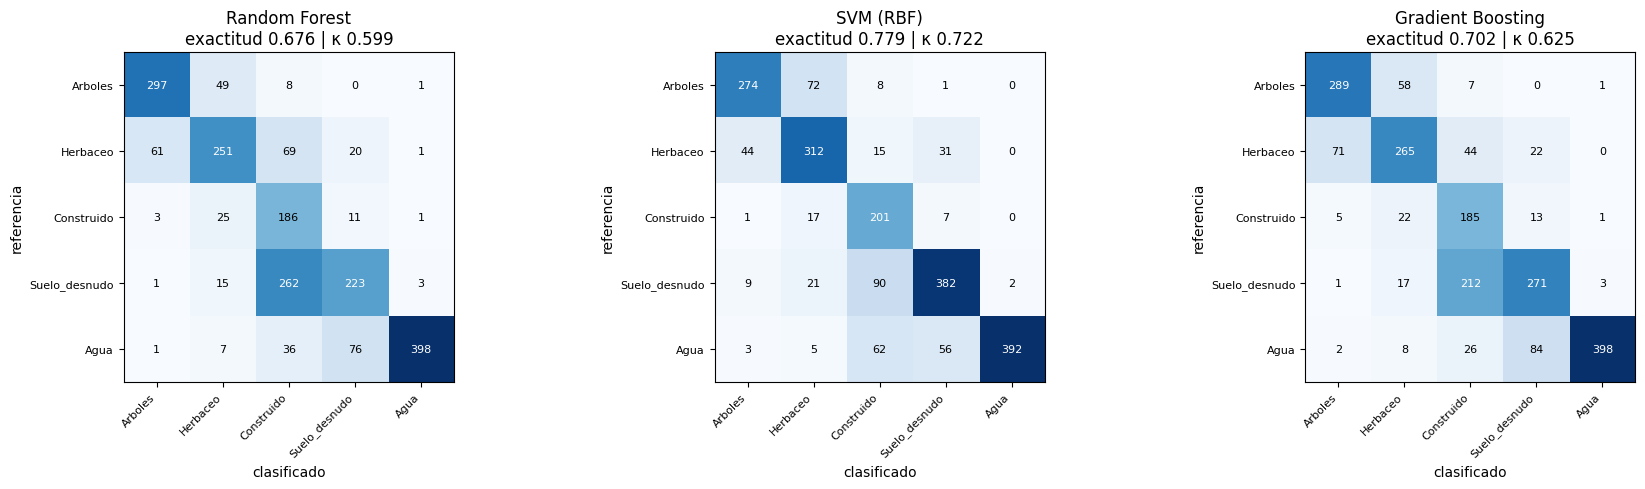

Random Forest – exactitud por clase:
        clase  exactitud_productor  exactitud_usuario
      Arboles                0.837              0.818
     Herbaceo                0.624              0.723
   Construido                0.823              0.332
Suelo_desnudo                0.442              0.676
         Agua                0.768              0.985


In [8]:
# Matrices de confusión y exactitudes por clase (productor = recall, usuario = precision)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nombre, m) in zip(axes, matrices.items()):
    ax.imshow(m, cmap="Blues"); ax.set_title(f"{nombre}\nexactitud {tabla.loc[nombre,'exactitud']:.3f} | κ {tabla.loc[nombre,'kappa']:.3f}")
    ax.set_xticks(range(5)); ax.set_yticks(range(5)); ax.set_xticklabels(CLASES.values(), rotation=45, ha="right", fontsize=8); ax.set_yticklabels(CLASES.values(), fontsize=8)
    ax.set_xlabel("clasificado"); ax.set_ylabel("referencia")
    for i in range(5):
        for j in range(5): ax.text(j, i, m[i, j], ha="center", va="center", color="white" if m[i, j] > m.max() / 2 else "black", fontsize=8)
plt.tight_layout(); plt.show()

m = matrices["Random Forest"]
por_clase = pd.DataFrame({"clase": CLASES.values(),
                          "exactitud_productor": np.diag(m) / m.sum(1).clip(1),
                          "exactitud_usuario": np.diag(m) / m.sum(0).clip(1)}).round(3)
print("Random Forest – exactitud por clase:"); print(por_clase.to_string(index=False))

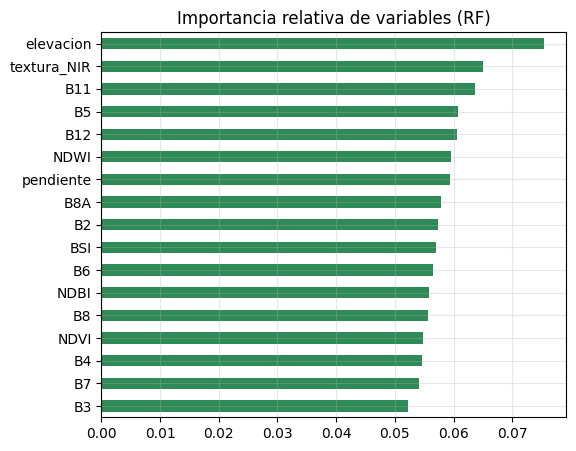

In [ ]:
# Importancia de variables del Random Forest (suma de la reducción de impureza por variable)
imp = pd.Series(modelos["Random Forest"].explain().get("importance").getInfo()).sort_values()
imp = imp / imp.sum()
imp.plot.barh(figsize=(6, 5), color="seagreen"); plt.title("Importancia relativa de variables (RF)"); plt.grid(alpha=.3); plt.show()

**Lectura esperada:** con validación espacial y referencia WorldCover, los tres clasificadores quedan entre 0,68 y
0,78 de exactitud con κ ≈ 0,60-0,72; en esta configuración la SVM (variables normalizadas) resultó la mejor y
RF/GBT quedaron cerca; con partición aleatoria todos superarían 0,85. Las confusiones se concentran
entre *herbáceo* y *árboles* (vegetación de transición) y entre *construido* y *suelo desnudo* (ahí la textura
ayuda). Recuerde que la referencia (WorldCover) tiene su propio error (~77 % global): parte de la "confusión" es
error de la referencia, y una partición aleatoria daría cifras más altas pero engañosas (ejercicio 4).

---
# Bloque 6. Posprocesamiento, áreas y exportación

Un **filtro de moda** (ventana 3×3) elimina píxeles aislados ("sal y pimienta"). Luego calculamos el área por clase
(`ee.Image.pixelArea`) y exportamos el mapa.

In [9]:
mejor = tabla["kappa"].idxmax()
mapa_final = mapas[mejor].focal_mode(radius=1, kernelType="square", units="pixels").rename("clase")
print("Mejor clasificador según κ:", mejor)

areas = (ee.Image.pixelArea().divide(1e6).addBands(mapa_final)
           .reduceRegion(ee.Reducer.sum().group(groupField=1, groupName="clase"), aoi, 30, maxPixels=1e10, tileScale=4).getInfo())
df_areas = pd.DataFrame(areas["groups"]).rename(columns={"sum": "km2"})
df_areas["clase"] = df_areas["clase"].map(CLASES); df_areas["%"] = (100 * df_areas["km2"] / df_areas["km2"].sum()).round(1)
print(df_areas.round(1).to_string(index=False))

# Descarga local a 60 m (la clasificación de 17 variables sobre 58 escenas es costosa; a 10-30 m la descarga directa
# puede exceder el tiempo límite). Para el mapa a 10 m use la tarea a Drive (ENVIAR_TAREA = True).
ruta = f"salidas_clase7/cobertura_{mejor.split()[0].lower()}_60m.tif"
try:
    geemap.ee_export_image(mapa_final.toByte(), filename=ruta, scale=60, region=aoi.bounds(), file_per_band=False)
    print("Exportado:", ruta, "(ábralo en QGIS con la paleta:", dict(zip(CLASES.values(), PALETA)), ")")
except Exception as e:
    print("La descarga directa falló (tiempo límite); use la tarea a Drive. Detalle:", str(e)[:120])
ENVIAR_TAREA = False
tarea = ee.batch.Export.image.toDrive(image=mapa_final.toByte(), description="cobertura_santander_10m", folder="BigData_Semana3",
                                      region=aoi.bounds(), scale=10, maxPixels=1e9, fileFormat="GeoTIFF")
if ENVIAR_TAREA:
    tarea.start(); print("Tarea enviada a Drive:", tarea.id)

Mejor clasificador según κ: SVM (RBF)
        clase   km2    %
      Arboles 764.3 59.3
     Herbaceo 427.0 33.1
   Construido  74.7  5.8
Suelo_desnudo  17.3  1.3
         Agua   4.9  0.4
Generating URL ...
Please wait ...
Data downloaded to /content/salidas_clase7/cobertura_svm_60m.tif
Exportado: salidas_clase7/cobertura_svm_60m.tif (ábralo en QGIS con la paleta: {'Arboles': '006400', 'Herbaceo': 'ffff4c', 'Construido': 'fa0000', 'Suelo_desnudo': 'b4b4b4', 'Agua': '0064c8'} )


---
# Síntesis

* Un flujo de clasificación supervisada completo corre **en la nube** sin descargar una sola escena.
* RF, SVM y GBT son intercambiables en la API (`ee.Classifier.*`); se comparan con **matriz de confusión, exactitud,
  Kappa y exactitudes por clase** sobre muestras **independientes y separadas espacialmente**.
* Textura y terreno mejoran la separación de clases espectralmente parecidas.
* La calidad de la referencia limita la exactitud medible.

### Referencias
* Congalton, R. G. y Green, K. (2019). *Assessing the Accuracy of Remotely Sensed Data* (3.ª ed.). CRC Press.
* Belgiu, M. y Drăguţ, L. (2016). Random forest in remote sensing: A review. *ISPRS J. Photogramm. Remote Sens.*, 114, 24-31.
* Mountrakis, G. et al. (2011). Support vector machines in remote sensing: A review. *ISPRS J.*, 66, 247-259.
* Zanaga, D. et al. (2022). ESA WorldCover 10 m 2021 v200. Documentación EE: https://developers.google.com/earth-engine/guides/classification